# YOLOv8n V1 No-Mosaic, Package Inspection
This notebook uses the trained YOLOv8n no-mosaic model to detect pork rasher packaging defects. It shows the input image beside the predicted bounding boxes, class labels and confidence scores. The inspection function, unit tests and HTML documentation are also included.
> Note: This notebook was reorganised after model training. It uses the existing model weights and does not retrain the model.
## Model Settings
| Setting | Value |
|:---|:---|
| Dataset | Roboflow Dataset V1 |
| Model | YOLOv8n, mosaic disabled |
| Image size | 640 × 640 |
| Confidence threshold | 0.201 |
| Output | Defect name, confidence, bounding box |

## 1. Setup
Model weights are loaded from Google Drive, from the folder `model_runs`.

In [1]:
%pip install -q ultralytics pytest pdoc pillow matplotlib

from pathlib import Path
from google.colab import drive

drive.mount("/content/drive")

PROJECT_ROOT = Path("/content/drive/MyDrive/MMA3001_Project")
WEIGHTS_PATH = PROJECT_ROOT / "model_runs/yolov8n_v1_no_mosaic/weights/best.pt"
CONFIDENCE = 0.201

if not WEIGHTS_PATH.is_file():
    raise FileNotFoundError(f"Model weights not found: {WEIGHTS_PATH}")

print("Model weights:", WEIGHTS_PATH)

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 47.0/47.0 kB 2.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.4/1.4 MB 23.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 100.0/100.0 kB 4.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 56.2/56.2 kB 2.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 97.6/97.6 kB 5.8 MB/s eta 0:00:00
Mounted at /content/drive
Model weights: /content/drive/MyDrive/MMA3001_Project/model_runs/yolov8n_v1_no_mosaic/weights/best.pt


## 2. Inspection Function
`inspection.py` contains the reusable function for defect detection. Bounding boxes use the pixel coordinates [x1, y1, x2, y2].

In [2]:
%%writefile inspection.py
"""
Detect pork rasher packaging defects in an image.
"""

from ultralytics import YOLO


def inspect_package(image_path, weights_path, confidence=0.201):
    """
    Detect packaging defects in an image.

    Args:
        image_path: Path to the input image.
        weights_path: Path to the trained YOLO weights.
        confidence: Minimum detection confidence.

    Returns:
        List of detections with defect name, confidence, and bounding box.
    """
    model = YOLO(str(weights_path))
    result = model.predict(
        source=str(image_path),
        conf=confidence,
        imgsz=640,
        verbose=False,
    )[0]

    detections = []
    for box in result.boxes:
        detections.append({
            "defect": result.names[int(box.cls.item())],
            "confidence": round(float(box.conf.item()), 3),
            "box": [round(float(x), 1) for x in box.xyxy[0].tolist()],
        })

    return detections

Writing inspection.py


## 3. Example Inference
One package image is uploaded and inspected. The original image and the annotated prediction are displayed side by side.

In [3]:
from google.colab import files
from inspection import inspect_package

uploaded = files.upload()
if not uploaded:
    raise ValueError("No input image was uploaded.")

image_path = Path(next(iter(uploaded)))
detections = inspect_package(image_path, WEIGHTS_PATH, confidence=CONFIDENCE)

print("Input image:", image_path.name)
print("Detections:", len(detections))
for detection in detections:
    print(detection)

Creating new Ultralytics Settings v0.0.8 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/usage/settings.


Saving frame_with_red_102_jpg.rf.10163b7e614de52a86d75cf0c2def998.jpg to frame_with_red_102_jpg.rf.10163b7e614de52a86d75cf0c2def998.jpg
Input image: frame_with_red_102_jpg.rf.10163b7e614de52a86d75cf0c2def998.jpg
Detections: 1
{'defect': 'unsealed', 'confidence': 0.629, 'box': [0.0, 330.8, 325.0, 539.5]}


## Input and Predicted Image
The bounding boxes and confidence labels are drawn from the detection output returned by inspect_package().

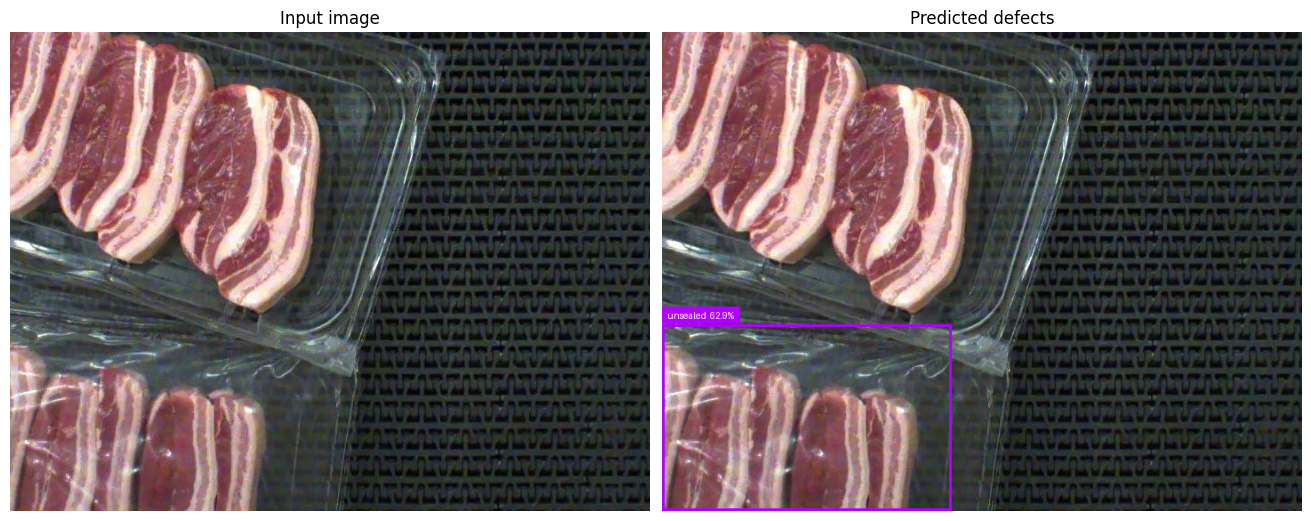

Saved figure: outputs/v1_inference_example.png


In [4]:
from pathlib import Path
from PIL import Image, ImageDraw, ImageFont
import matplotlib.pyplot as plt


def draw_detections(image, predictions):
    """
    Draw defect bounding boxes and confidence labels.

    Args:
        image: Input PIL image.
        predictions: Detections returned by `inspect_package()`.

    Returns:
        Annotated PIL image.
    """
    annotated = image.copy()
    draw = ImageDraw.Draw(annotated)
    width, height = image.size
    line_width = max(2, round(min(width, height) * 0.006))
    font_size = max(15, round(min(width, height) * 0.033))

    try:
        font = ImageFont.truetype("DejaVuSans.ttf", font_size)
    except OSError:
        font = ImageFont.load_default()

    for item in predictions:
        x1, y1, x2, y2 = item["box"]
        x1, x2 = sorted((max(0, min(width, x1)), max(0, min(width, x2))))
        y1, y2 = sorted((max(0, min(height, y1)), max(0, min(height, y2))))
        color = "#B000FF"
        draw.rectangle((x1, y1, x2, y2), outline=color, width=line_width)

        label = f"{item['defect']}  {item['confidence']:.1%}"
        bounds = draw.textbbox((0, 0), label, font=font)
        text_width = bounds[2] - bounds[0]
        text_height = bounds[3] - bounds[1]
        label_x = max(0, min(x1, width - text_width - 12))
        label_y = max(0, y1 - text_height - 12)
        draw.rectangle(
            (label_x, label_y, label_x + text_width + 12, label_y + text_height + 10),
            fill=color,
        )
        draw.text((label_x + 6, label_y + 3), label, fill="white", font=font)

    return annotated


original = Image.open(image_path).convert("RGB")
annotated = draw_detections(original, detections)

fig, axes = plt.subplots(1, 2, figsize=(13, 5.5), constrained_layout=True)
for ax, image, title in zip(
    axes,
    (original, annotated),
    ("Input image", "Predicted defects"),
):
    ax.imshow(image)
    ax.set_title(title)
    ax.axis("off")

output_dir = Path("outputs")
output_dir.mkdir(exist_ok=True)
figure_path = output_dir / "v1_inference_example.png"
fig.savefig(figure_path, dpi=170, bbox_inches="tight")
plt.show()
print("Saved figure:", figure_path)

## 4. Automated Tests
The unit tests check the inspection output for zero detections and one detection. Mock predictions are used, so the tests do not measure model accuracy.

In [5]:
%%writefile test_inspection.py
"""
Tests for the packaging inspection function.
"""

from unittest.mock import MagicMock, patch
from inspection import inspect_package


def test_no_detections():
    """
    Return an empty list when no defects are detected.
    """
    fake_model = MagicMock()
    fake_model.predict.return_value = [MagicMock(boxes=[])]

    with patch("inspection.YOLO", return_value=fake_model):
        result = inspect_package("example.jpg", "best.pt")

    assert result == []


def test_one_detection():
    """
    Return the correct detection fields and values.
    """
    fake_box = MagicMock()
    fake_box.cls.item.return_value = 3
    fake_box.conf.item.return_value = 0.629
    fake_box.xyxy[0].tolist.return_value = [0, 330.8, 325, 539.5]

    fake_result = MagicMock()
    fake_result.boxes = [fake_box]
    fake_result.names = {3: "unsealed"}

    fake_model = MagicMock()
    fake_model.predict.return_value = [fake_result]

    with patch("inspection.YOLO", return_value=fake_model):
        result = inspect_package("example.jpg", "best.pt")

    assert result == [{
        "defect": "unsealed",
        "confidence": 0.629,
        "box": [0.0, 330.8, 325.0, 539.5],
    }]

Writing test_inspection.py


In [6]:
import subprocess
import sys

with Path("test_report.txt").open("w", encoding="utf-8") as report_file:
    test_run = subprocess.run(
        [sys.executable, "-m", "pytest", "-v", "test_inspection.py"],
        stdout=report_file,
        stderr=subprocess.STDOUT,
        text=True,
        check=False,
    )

print(Path("test_report.txt").read_text(encoding="utf-8"))
assert test_run.returncode == 0, "Inspection tests failed."

============================= test session starts ==============================
platform linux -- Python 3.13.15, pytest-8.4.2, pluggy-1.7.0 -- /usr/bin/python3
cachedir: .pytest_cache
rootdir: /content
plugins: typeguard-4.6.0, anyio-4.15.1, langsmith-0.14.11, platformdirs-4.13.3
collecting ... collected 2 items

test_inspection.py::test_no_detections PASSED                            [ 50%]
test_inspection.py::test_one_detection PASSED                            [100%]

============================== 2 passed in 1.60s ===============================



## 5. HTML Documentation
`pdoc` generates HTML documentation from the docstrings in `inspection.py`.

In [7]:
!python -m pdoc inspection.py -o docs
print("HTML files:", sorted(str(p) for p in Path("docs").glob("*.html")))

Warn: Suppressed execution of ('/usr/sbin/ip', 'link') during import. Set PDOC_ALLOW_EXEC=1 as an environment variable to allow subprocess execution. (/usr/lib/python3.13/uuid.py:382)
Warn: Suppressed execution of ('/usr/sbin/ifconfig',) during import. Set PDOC_ALLOW_EXEC=1 as an environment variable to allow subprocess execution. (/usr/lib/python3.13/uuid.py:382)
Warn: Suppressed execution of ('/usr/sbin/ifconfig', '-a') during import. Set PDOC_ALLOW_EXEC=1 as an environment variable to allow subprocess execution. (/usr/lib/python3.13/uuid.py:382)
Warn: Suppressed execution of ('/usr/sbin/ifconfig', '-av') during import. Set PDOC_ALLOW_EXEC=1 as an environment variable to allow subprocess execution. (/usr/lib/python3.13/uuid.py:382)
HTML files: ['docs/index.html', 'docs/inspection.html']


## 6. Export Files
The inspection source, test report, HTML documentation and annotated example image are saved in the Colab runtime. Downloads are optional.

In [8]:
from google.colab import files

export_files = [
    Path("inspection.py"),
    Path("test_inspection.py"),
    Path("test_report.txt"),
    Path("docs/inspection.html"),
    Path("docs/index.html"),
    figure_path,
]

for path in export_files:
    print(f"{path}: {'available' if path.is_file() else 'missing'}")

DOWNLOAD_EXPORTS = False
if DOWNLOAD_EXPORTS:
    for path in export_files:
        if path.is_file():
            files.download(str(path))

inspection.py: available
test_inspection.py: available
test_report.txt: available
docs/inspection.html: available
docs/index.html: available
outputs/v1_inference_example.png: available


## Limitations
The displayed prediction is a demonstration on one image, not a measure of overall detection accuracy. Results depend on the trained weights and confidence threshold. Model performance is assessed separately using the V1 test set.